# 10 · Caustic crossings: starting points from the crossing times

When the source crosses a caustic, the light curve jumps up at the **entry** and drops at the **exit**. These two
times are easy to read off the data, and they pin down the trajectory almost completely: for a given (s, q), every
pair of points on the caustic defines one straight trajectory that is on the caustic at both times, and that fixes
α, u0, tE and t0 (the caustic-crossing parameterisation of Cassan 2008; MulensModel's "uniform caustic sampling").

lenscape uses this to build **starting points** for its fits: set `cfg["caustic_crossings"] = (t_in, t_out)` and the
best few of these trajectories (by χ²) are fitted along with the usual screen of 20 trajectory angles.

This notebook shows when it matters: fitting a caustic-crossing event from a rough start.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import lenscape
from lenscape import config, figures, caustics

## A simulated caustic-crossing event

A planet near the Einstein ring (s ≈ 1, q = 0.004): the source crosses the resonant caustic. Two telescopes with
different source and blend fluxes, nightly coverage plus dense coverage of the anomaly.

In [2]:
truth = np.array([0.0, -0.025, 35.0, 0.002, -2.4, 4.41, -3.3])     # t0, u0, tE, log s, log q, alpha, log rho
backend = lenscape.make_backend(config.REFINE_BACKEND)
rng = np.random.default_rng(2)
t = np.sort(np.r_[rng.uniform(-80, 80, 300), rng.uniform(-4, 4, 300)])
idx = (np.arange(len(t)) % 2).astype(int)
fs, fb, err = np.array([1000.0, 600.0]), np.array([300.0, -100.0]), np.where(idx == 0, 30.0, 25.0)
data = lenscape.Data(t, fs[idx] * backend.lc(truth, t) + fb[idx] + rng.normal(0, err), err, idx, ["T1", "T2"])
print(f"chi2 of the true model: {lenscape.model.chi2(backend, truth, data):.1f} for {len(data)} points")

chi2 of the true model: 620.3 for 600 points


## Reading the crossing times

The entry is the sudden rise, the exit the sharp drop at the end of the "U" between them. Here we read them off
the zoom (to a few hundredths of a day — the starting points only need to be close).

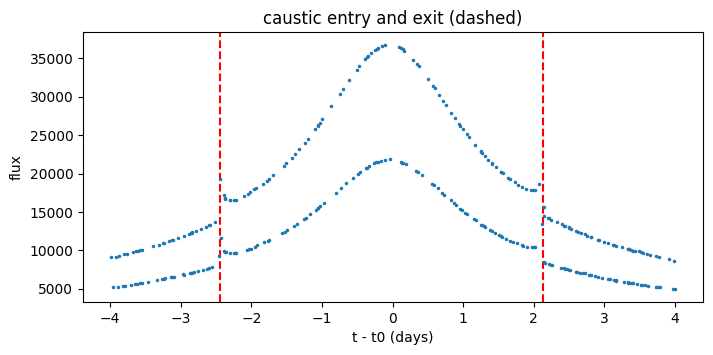

In [3]:
t_in, t_out = -2.44, 2.13                                            # read off the plot below
fig, ax = plt.subplots(figsize=(8, 3.5))
k = np.abs(data.t) < 4
ax.errorbar(data.t[k], data.f[k], data.e[k], fmt=".", ms=3)
for tc in (t_in, t_out):
    ax.axvline(tc, color="r", ls="--")
ax.set_xlabel("t - t0 (days)"); ax.set_ylabel("flux"); ax.set_title("caustic entry and exit (dashed)");

## Fitting from a rough start

A single-lens fit gives only rough values (here t_E = 25 days instead of 35). We fit at the true (s, q) once with
the angle screen alone and once with caustic-crossing starts added.

In [4]:
seed = dict(t0=0.3, u0=0.06, tE=25.0, logrho=-3.0)                  # rough start
ls, lq = truth[3], truth[4]
for name, extra in (("angle screen", {}), ("+ caustic starts", dict(caustic_crossings=(t_in, t_out)))):
    cfg = dict(config.DEFAULT, seed=seed, **extra)
    t1 = time.time()
    chi2, x = lenscape.fit.fit_point(ls, lq, data, cfg)
    print(f"{name:18s}: chi2 = {chi2:10.1f}   tE = {x[2]:5.2f}   alpha = {x[3]:.3f}   ({time.time() - t1:.1f} s)")
    if extra:
        found = np.r_[x[:3], ls, lq, x[3], x[4]]

angle screen      : chi2 =   292834.3   tE = 19.43   alpha = 2.931   (6.7 s)


+ caustic starts  : chi2 =      618.0   tE = 35.00   alpha = 1.873   (11.5 s)


The angle screen keeps t0, u0, tE and ρ of the start and only tries 20 trajectory angles; with a wrong t_E no
angle produces the caustic crossings at the right times, and the fit ends in a poor local minimum. The
caustic-crossing starts have the right timing by construction; the best of them are then refined by moving their
entry and exit points along the caustic, and the fit converges to the true solution.

## The solution

The trajectory of the solution enters and leaves the caustic at the times we read off:

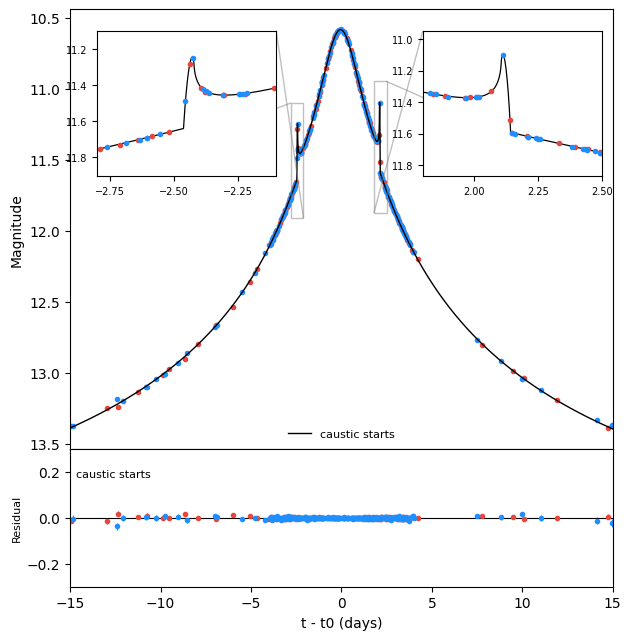

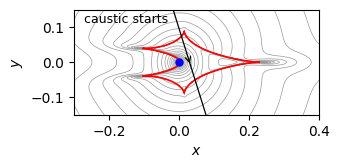

In [5]:
figures.plot_lightcurve(backend, [found], data, labels=["caustic starts"], window=(-15, 15), insets=[(-2.8, -2.1), (1.8, 2.5)],
                        xlabel="t - t0 (days)");
figures.plot_geometry([found], labels=["caustic starts"], ncols=1, extent=(-0.3, 0.4, -0.15, 0.15));

## A real event: MOA-2022-BLG-091

With the public KMTNet data, the caustic entry and exit of MOA-2022-BLG-091 are at HJD' ≈ 9655.27 and 9659.93
(Han et al. 2025). From a rough single-lens start, the full fit with caustic starts finds the planetary solution:

In [6]:
moa = lenscape.datasets.kmtnet("KMT-2022-BLG-0114", window=(9600, 9720))
seed = dict(t0=9657.5, u0=-0.05, tE=25.0, logrho=-3.0)              # rough single-lens values
ls, lq = 0.002, -2.4                                                 # a point near s = 1, q = 0.004
for name, extra in (("angle screen", {}), ("+ caustic starts", dict(caustic_crossings=(9655.27, 9659.93)))):
    cfg = dict(config.DEFAULT, seed=seed, **extra)
    chi2, x = lenscape.fit.fit_point(ls, lq, moa, cfg)
    print(f"{name:18s}: chi2 = {chi2:9.1f}   tE = {x[2]:5.2f}   alpha = {x[3]:.3f}")
chi2, best = lenscape.fit_full(moa, np.r_[x[:3], ls, lq, x[3], x[4]])
print(f"full fit: chi2 = {chi2:.1f}, s = {10 ** best[3]:.4f}, q = {10 ** best[4]:.2e}, alpha = {best[5]:.3f}, tE = {best[2]:.2f}")

angle screen      : chi2 =    3111.1   tE = 33.65   alpha = 4.849


+ caustic starts  : chi2 =    2764.4   tE = 35.93   alpha = 1.918


full fit: chi2 = 2760.3, s = 1.0035, q = 4.45e-03, alpha = 1.961, tE = 34.32


The angle screen stops in a poor local minimum; the caustic starts lead to the planetary solution, Sol B of Han et al. (2025): s = 1.0033, q = 4.36 × 10⁻³. Its α here is the mirror image of the paper's, (u0, α) → (−u0, −α), which gives the same light curve (the same holds for the simulated event above).

## When to use it

* **Use it** for events with resolved caustic crossings when you do not yet have a good solution: a new event, a
  first search, or fits far from the best solution. It finds solutions the angle screen misses.
* **Not needed for maps** that start from a best fit (`lattice`, `densify`): there the starting points are already
  good, caustic starts help little and roughly double the cost of each fit.
* **Never alone** (`caustic_only=True`) over a whole map: the crossing times belong to the true solution, not to
  every (s, q); away from it the best trajectory need not cross the caustic at these times.

Options: `cfg["n_caustic"]` (starting points kept, default 4), `cfg["caustic_samples"]` (points per caustic,
default 24), `cfg["caustic_refine"]` (default True: the best candidates are first optimised along the caustic, entry
and exit points moving continuously, which makes the method robust to errors of a few hundredths of a day in the
crossing times), and several crossing pairs as a list
`[(t_in1, t_out1), (t_in2, t_out2)]`. `lenscape.fit.caustic_starts(log s, log q, (t_in, t_out))` returns the
candidate vectors themselves.